### 1. import library yg dibutuhkan

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras import layers
from tensorflow.keras.layers import Dropout
from tensorflow.keras.utils import image_dataset_from_directory

### 2. Muat data

#### Data Train

In [2]:
train_ds = image_dataset_from_directory('seg_train/seg_train',image_size = (150,150), batch_size = 32)

Found 14014 files belonging to 6 classes.


#### Data Test

In [3]:
test_ds = image_dataset_from_directory('seg_test/seg_test',image_size = (150,150), batch_size = 32)

Found 2985 files belonging to 6 classes.


### 3. Melihat Nama Kelas Data Train dan test

#### Data train

In [4]:
class_names = train_ds.class_names
print('Nama Kelas :', class_names)

Nama Kelas : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


#### Data test

In [5]:
class_names = test_ds.class_names
print('Nama Kelas :', class_names)

Nama Kelas : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


### 4. Preprocessing

cek piksel

In [6]:
for images, labels in train_ds.take(1):
    print("Nilai minimum piksel:", tf.reduce_min(images).numpy())
    print("Nilai maksimum piksel:", tf.reduce_max(images).numpy())
    break

Nilai minimum piksel: 0.0
Nilai maksimum piksel: 255.0


#### normalisasi piksel

In [7]:
normalization_layer = tf.keras.layers.Rescaling(1./255.0)
train_ds = train_ds.map(lambda x, y:(normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x),y))


### 5. Membangun Model CNN

In [8]:
model = Sequential([RandomFlip('horizontal', input_shape=(150,150,3)),
                    RandomRotation(0.1),
                    RandomZoom(0.1),
                    Conv2D(32, (3,3), activation ='relu'),
                    MaxPooling2D((2,2)),
                    Conv2D(64, (3,3), activation ='relu'),
                    MaxPooling2D((2,2)),
                    Conv2D(128, (3,3),activation = 'relu'),
                    MaxPooling2D((2,2)),
                    Flatten(),
                    Dense(256, activation='relu'),
                    Dropout(0.5),
                    Dense(128, activation='relu'),
                    Dropout(0.5),
                    Dense(len(class_names),activation='softmax')])

model.summary()

c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     9,470,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,597,126 (36.61 MB)

 Trainable params: 9,597,126 (36.61 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

### 6. Latih model Train

In [10]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(train_ds,validation_data=test_ds,epochs=200,callbacks=[early_stop])

Epoch 1/200


c:\Users\MyBook Hype\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


438/438 ━━━━━━━━━━━━━━━━━━━━ 512s 1s/step - accuracy: 0.5103 - loss: 1.2347 - val_accuracy: 0.6245 - val_loss: 1.0051
Epoch 2/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 584s 1s/step - accuracy: 0.6452 - loss: 0.9702 - val_accuracy: 0.7042 - val_loss: 0.7831
Epoch 3/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 493s 1s/step - accuracy: 0.6976 - loss: 0.8472 - val_accuracy: 0.7782 - val_loss: 0.6290
Epoch 4/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 524s 1s/step - accuracy: 0.7324 - loss: 0.7614 - val_accuracy: 0.7883 - val_loss: 0.5952
Epoch 5/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 565s 1s/step - accuracy: 0.7451 - loss: 0.7276 - val_accuracy: 0.8064 - val_loss: 0.5511
Epoch 6/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 651s 1s/step - accuracy: 0.7642 - loss: 0.6831 - val_accuracy: 0.7977 - val_loss: 0.5606
Epoch 7/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 502s 1s/step - accuracy: 0.7689 - loss: 0.6661 - val_accuracy: 0.7809 - val_loss: 0.6309
Epoch 8/200
438/438 ━━━━━━━━━━━━━━━━━━━━ 537s 1s/step - accuracy: 0.7751 - loss: 0.6472 - val_accuracy

### 7. Evaluasi Model


#### model train

In [11]:
train_loss, train_accuracy =model.evaluate(train_ds)
print('Train loss :', train_loss)
print('Train Accuracy :',train_accuracy)

438/438 ━━━━━━━━━━━━━━━━━━━━ 119s 272ms/step - accuracy: 0.8399 - loss: 0.4524
Train loss : 0.4523918330669403
Train Accuracy : 0.8398743867874146


model test

In [12]:
test_loss , test_accuracy = model.evaluate(test_ds)
print('Test loss :',test_loss)
print('Test Accuracy :', test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 28s 295ms/step - accuracy: 0.8288 - loss: 0.4952
Test loss : 0.4951740801334381
Test Accuracy : 0.8288106918334961


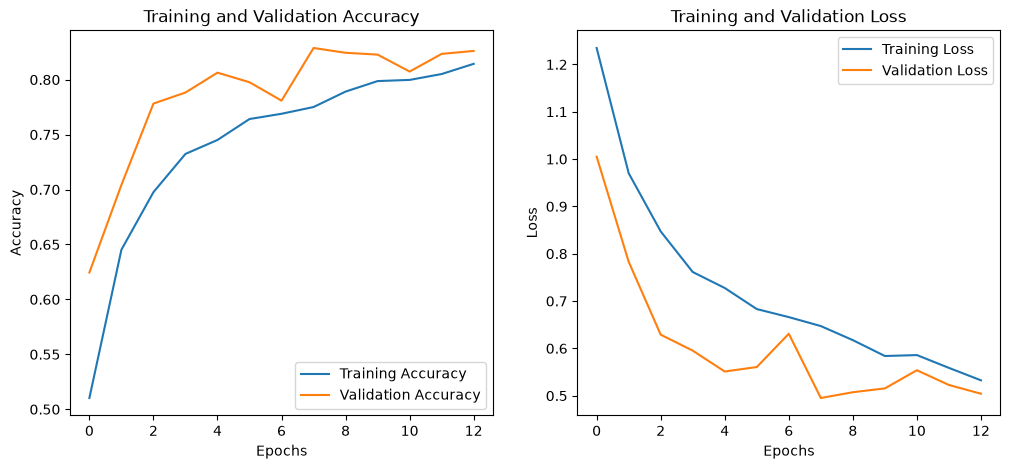

In [13]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))
# 1. Grafik Akurasi (Training vs Validation)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

# 2. Grafik Loss (Training vs Validation)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.savefig('images/learning_curve.png', dpi=300, bbox_inches='tight')

plt.show()

#### 8. Confusion Matrix

Confusion matrix berhasil disimpan sebagai 'confusion_matrix.png'


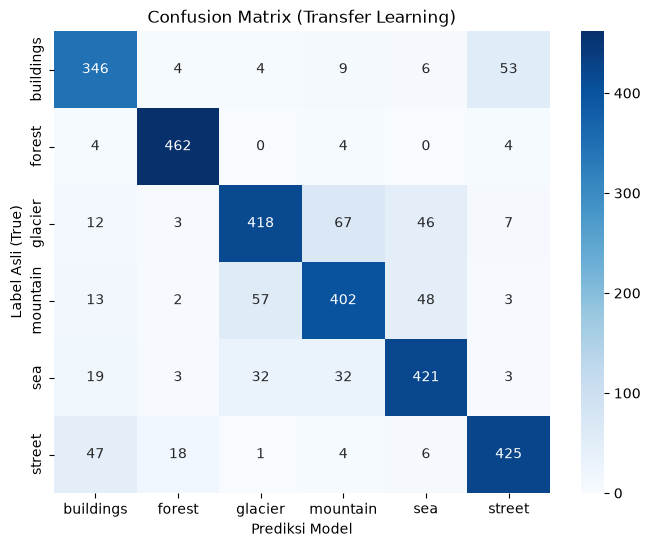


--- Classification Report ---
              precision    recall  f1-score   support

   buildings       0.78      0.82      0.80       422
      forest       0.94      0.97      0.96       474
     glacier       0.82      0.76      0.78       553
    mountain       0.78      0.77      0.77       525
         sea       0.80      0.83      0.81       510
      street       0.86      0.85      0.85       501

    accuracy                           0.83      2985
   macro avg       0.83      0.83      0.83      2985
weighted avg       0.83      0.83      0.83      2985



In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Mengumpulkan semua label asli (true labels) dan hasil prediksi dari test_ds
true_labels = []
predicted_labels = []  

for images, labels in test_ds:
    # Prediksi menggunakan model
    preds = model.predict(images, verbose=0)
    pred_classes = np.argmax(preds, axis=1)
    
    # Masukkan ke dalam list
    true_labels.extend(labels.numpy())
    predicted_labels.extend(pred_classes)

# 2. Menghitung Confusion Matrix
cm = confusion_matrix(true_labels, predicted_labels)

# 3. Menampilkan Confusion Matrix dengan Seaborn Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title('Confusion Matrix (Transfer Learning)')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Asli (True)')

# Simpan gambar confusion matrix
plt.savefig('images/confusion_matrix.png', dpi=300, bbox_inches='tight')
print("Confusion matrix berhasil disimpan sebagai 'confusion_matrix.png'")

plt.show()

# 4. (Opsional) Menampilkan Laporan Klasifikasi (Precision, Recall, F1-Score per kelas)
print("\n--- Classification Report ---")
print(classification_report(true_labels, predicted_labels, target_names=class_names))